# PEMETAAN TIPOLOGI DAN PROYEKSI KESENJANGAN DIGITAL ANTARPROVINSI DI INDONESIA

**Tim: Afinity**

In [1]:
# ==========================================
# 0. SETUP: INSTALL & IMPORT LIBRARY
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# Forecasting & Time Series
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from statsmodels.tsa.api import Holt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set Konfigurasi Visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('crest')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. BUSINESS UNDERSTANDING

### 1.1 Latar Belakang & Kerangka Kerja Metodologi CRISP-DM
Kesenjangan digital (*digital divide*) merupakan tantangan strategis di Indonesia. Laju adopsi infrastruktur teknologi informasi dan komunikasi (TIK) menunjukkan ketimpangan geografis antarwilayah dan kawasan perkotaan-perdesaan. Analisis data mining ini disusun secara ketat mengikuti 6 fase standar CRISP-DM:

### 1.2 Rumusan Masalah
1. Bagaimana pemetaan kelompok (klaster) tingkat kesenjangan digital di **38 Provinsi Indonesia pada tahun 2025** berdasarkan evaluasi $K$ obyektif?
2. Berapa jumlah cluster optimum ($K$) yang terbentuk secara obyektif berdasarkan metrik evaluasi statistik (Silhouette, Davies-Bouldin, Calinski-Harabasz, Elbow Inertia) serta interpretasi domain TIK?
3. Bagaimana tren disparitas adopsi teknologi 2022–2025, termasuk analisis pendukung ketimpangan perkotaan vs perdesaan (*urban-rural*)?
4. Bagaimana performa model forecasting (Linear Regression, Polynomial Regression, Holt Exponential Smoothing) pada ke-5 indikator digital?
5. Bagaimana hasil proyeksi (*forecasting*) ke-5 indikator digital untuk **34 Provinsi** periode tahun **2026 hingga 2029**?

### 1.3 Tujuan Penelitian
* Melakukan klusterisasi 38 provinsi berdasarkan 5 fitur utama TIK tahun 2025 secara obyektif ($K=3$: Tinggi, Sedang, Rendah).
* Membandingkan metode K-Means, Agglomerative Clustering, dan Gaussian Mixture Model secara objektif pada $K$ final terpilih.
* Membangun model proyeksi time-series 2026–2029 untuk ke-5 indikator pada 34 provinsi (training 2022–2024, testing 2025, retraining 2022–2025).
* Menyusun insight berbasis bukti statistik serta mengamankan model terlatih dan dataset hasil pemetaan.

# 2. DATA UNDERSTANDING

### 2.1 Pemuatan Single Master Dataset & Subsetting Dinamis
Menggunakan 1 Master Dataset utama `dataset_BPS_telekomunikasi_2022_2025_lengkap.csv` (152 baris, 38 provinsi, 2022–2025) sebagai *Single Source of Truth*.

In [2]:
# DATA UNDERSTANDING: LOAD MASTER DATASET & PEMISAHAN SUBSET

file_master = 'dataset_BPS_telekomunikasi_2022_2025_lengkap.csv'
df_master = pd.read_csv(file_master)

# 1. Definisi 5 Fitur Utama TIK
features_clustering = [
    'Penduduk_Akses_Internet',
    'Penduduk_Telepon_Seluler',
    'Penduduk_Menggunakan_Komputer',
    'Rumah_Tangga_Komputer',
    'Rumah_Tangga_Akses_Internet'
]

# 2. Pemisahan Subset Clustering (38 Provinsi, Tahun 2025, 5 Fitur Utama)
df_cluster = df_master[df_master['Tahun'] == 2025][['Provinsi'] + features_clustering].reset_index(drop=True)

# 3. Pemisahan Subset Forecasting (34 Provinsi Induk, 2022-2025 dengan data histori lengkap)
provs_complete = df_master.groupby('Provinsi')['Penduduk_Akses_Internet'].count().loc[lambda x: x == 4].index
df_forecast = df_master[df_master['Provinsi'].isin(provs_complete)][['Provinsi', 'Tahun'] + features_clustering].reset_index(drop=True)

print(f'[DATA MASTER LOADED] Shape: {df_master.shape} | Rentang Tahun: {df_master["Tahun"].min()}-{df_master["Tahun"].max()}')
print(f'[SUBSET CLUSTERING 2025 DERIVED] Shape: {df_cluster.shape} | Jumlah Provinsi: {df_cluster["Provinsi"].nunique()}')
print(f'[SUBSET FORECASTING DERIVED] Shape: {df_forecast.shape} | Jumlah Provinsi: {df_forecast["Provinsi"].nunique()} | Tahun: {df_forecast["Tahun"].min()}-{df_forecast["Tahun"].max()}')

display(df_master.head())

[DATA MASTER LOADED] Shape: (152, 13) | Rentang Tahun: 2022-2025
[SUBSET CLUSTERING 2025 DERIVED] Shape: (38, 6) | Jumlah Provinsi: 38
[SUBSET FORECASTING DERIVED] Shape: (136, 7) | Jumlah Provinsi: 34 | Tahun: 2022-2025


,Provinsi,Tahun,Penduduk_Menggunakan_Komputer,Penduduk_Telepon_Seluler_Perkotaan,Penduduk_Telepon_Seluler_Perdesaan,Penduduk_Telepon_Seluler,Penduduk_Akses_Internet_Perkotaan,Penduduk_Akses_Internet_Perdesaan,Penduduk_Akses_Internet,Rumah_Tangga_Komputer,Rumah_Tangga_Akses_Internet,Gap_Akses_Internet_Urban_Rural,Gap_Telepon_Urban_Rural
0,Aceh,2022,8.97,70.22,58.77,62.65,62.74,48.42,52.99,13.70,79.85,14.32,11.45
1,Aceh,2023,9.32,70.14,59.02,62.87,69.43,53.93,59.30,15.10,86.46,15.50,11.12
2,Aceh,2024,9.37,70.57,61.41,64.64,70.80,58.66,62.93,15.49,88.95,12.14,9.16
3,Aceh,2025,10.14,75.22,64.30,68.21,77.51,65.87,70.03,17.59,91.91,11.64,10.92
4,Sumatera Utara,2022,10.83,72.21,61.93,67.71,70.43,59.55,65.68,15.41,86.61,10.88,10.28


In [3]:
# STRUKTUR DATA & DATA QUALITY CHECK

print('=== TIPE DATA & MISSING VALUES DATASET CLUSTERING (2025) ===')
print(df_cluster.info())
print('\nMissing values count:')
print(df_cluster.isnull().sum())
print(f'Jumlah data duplikat: {df_cluster.duplicated().sum()}')

print('\n=== TIPE DATA & MISSING VALUES DATASET FORECASTING (2022-2025) ===')
print(df_forecast.info())
print('\nMissing values count:')
print(df_forecast.isnull().sum())
print(f'Jumlah data duplikat: {df_forecast.duplicated().sum()}')

=== TIPE DATA & MISSING VALUES DATASET CLUSTERING (2025) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Provinsi                       38 non-null     object 
 1   Penduduk_Akses_Internet        38 non-null     float64
 2   Penduduk_Telepon_Seluler       38 non-null     float64
 3   Penduduk_Menggunakan_Komputer  38 non-null     float64
 4   Rumah_Tangga_Komputer          38 non-null     float64
 5   Rumah_Tangga_Akses_Internet    38 non-null     float64
dtypes: float64(5), object(1)
memory usage: 1.9+ KB
None

Missing values count:
Provinsi                         0
Penduduk_Akses_Internet          0
Penduduk_Telepon_Seluler         0
Penduduk_Menggunakan_Komputer    0
Rumah_Tangga_Komputer            0
Rumah_Tangga_Akses_Internet      0
dtype: int64
Jumlah data duplikat: 0

=== TIPE DATA & MISSING VALUE

In [4]:
# STATISTIK DESKRIPTIF

print('=== STATISTIK DESKRIPTIF 5 FITUR CLUSTERING (38 PROVINSI - 2025) ===')
display(df_cluster[features_clustering].describe().T[['mean', 'std', 'min', '50%', 'max']])

=== STATISTIK DESKRIPTIF 5 FITUR CLUSTERING (38 PROVINSI - 2025) ===


,mean,std,min,50%,max
Penduduk_Akses_Internet,73.21,14.11,15.40,76.57,91.32
Penduduk_Telepon_Seluler,68.99,11.40,22.49,70.18,84.47
Penduduk_Menggunakan_Komputer,12.36,3.96,1.33,11.75,23.41
Rumah_Tangga_Komputer,19.93,6.72,1.96,18.46,38.42
Rumah_Tangga_Akses_Internet,88.87,13.97,26.61,92.56,98.41


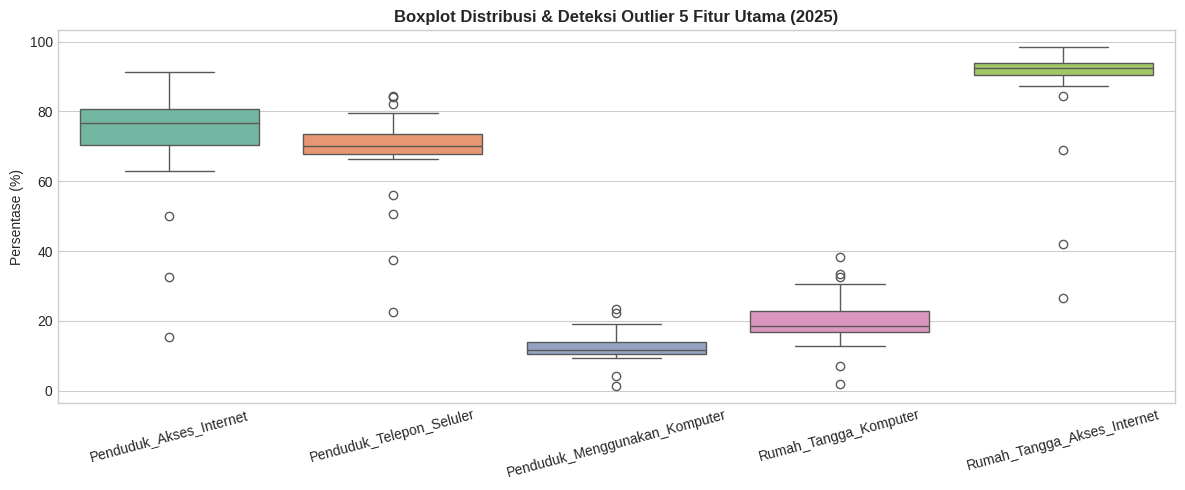

In [5]:
# Boxplot Distribusi & Outlier
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_cluster[features_clustering], palette='Set2')
plt.xticks(rotation=15)
plt.title('Boxplot Distribusi & Deteksi Outlier 5 Fitur Utama (2025)', fontsize=12, fontweight='bold')
plt.ylabel('Persentase (%)')
plt.tight_layout()
plt.show()

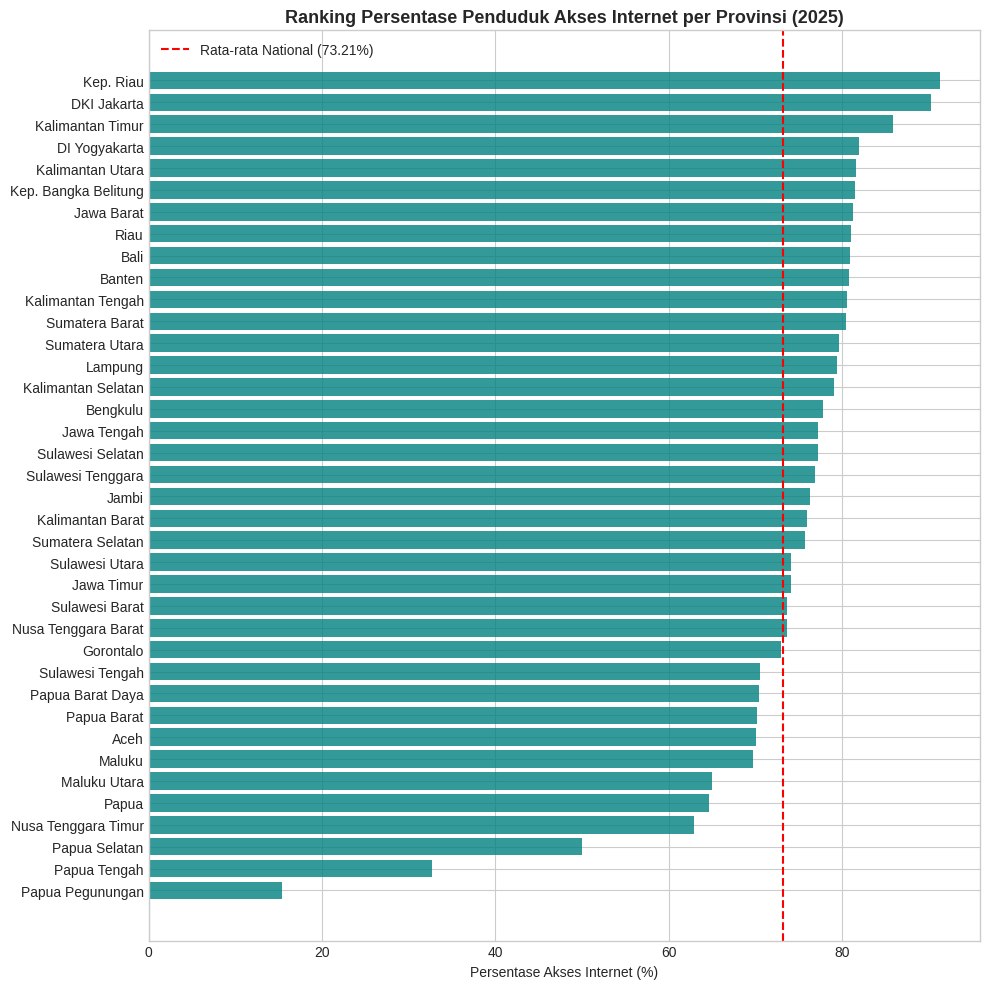

In [6]:
# RANKING PROVINSI & MATRIKS KORELASI (2025)
# Ranking Provinsi berdasarkan Akses Internet 2025
df_sorted = df_cluster.sort_values(by='Penduduk_Akses_Internet', ascending=True)
plt.figure(figsize=(10, 10))
plt.barh(df_sorted['Provinsi'], df_sorted['Penduduk_Akses_Internet'], color='teal', alpha=0.8)
plt.axvline(df_sorted['Penduduk_Akses_Internet'].mean(), color='red', linestyle='--', label=f'Rata-rata National ({df_sorted["Penduduk_Akses_Internet"].mean():.2f}%)')
plt.title('Ranking Persentase Penduduk Akses Internet per Provinsi (2025)', fontsize=13, fontweight='bold')
plt.xlabel('Persentase Akses Internet (%)')
plt.legend()
plt.tight_layout()
plt.show()

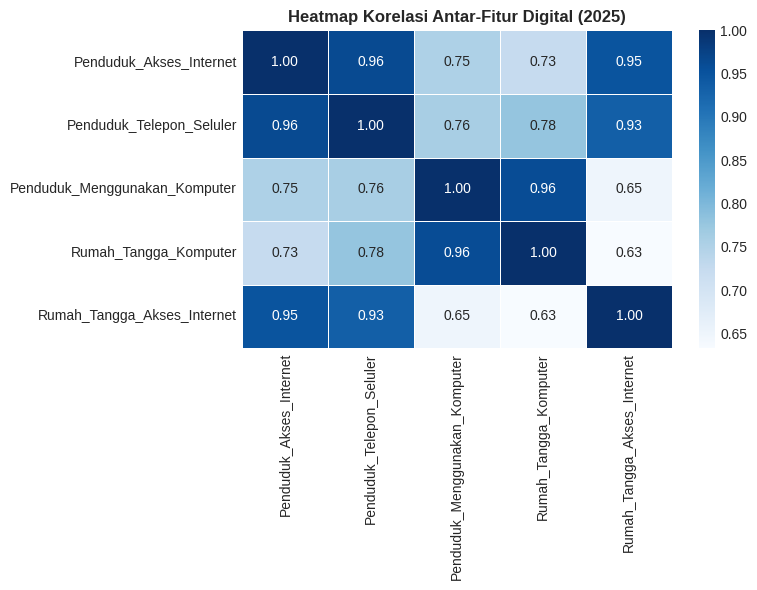

In [7]:
# Heatmap Korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(df_cluster[features_clustering].corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar-Fitur Digital (2025)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

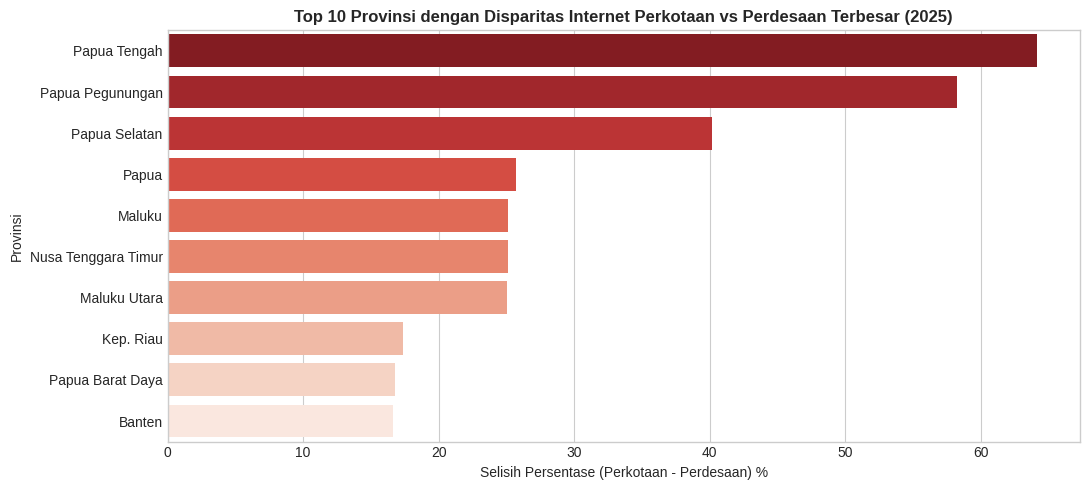

In [8]:
# ANALISIS KESENJANGAN URBAN-RURAL (PENDUKUNG EDA)
df_ur = df_master.dropna(subset=['Gap_Akses_Internet_Urban_Rural'])
df_ur_2025 = df_ur[df_ur['Tahun'] == 2025].sort_values(by='Gap_Akses_Internet_Urban_Rural', ascending=False)

plt.figure(figsize=(11, 5))
sns.barplot(data=df_ur_2025.head(10), x='Gap_Akses_Internet_Urban_Rural', y='Provinsi', palette='Reds_r')
plt.title('Top 10 Provinsi dengan Disparitas Internet Perkotaan vs Perdesaan Terbesar (2025)', fontsize=12, fontweight='bold')
plt.xlabel('Selisih Persentase (Perkotaan - Perdesaan) %')
plt.tight_layout()
plt.show()

# 3. DATA PREPARATION

### 3.1 Standardisasi Fitur (`StandardScaler`)
Standardisasi fitur dilakukan pada 5 fitur clustering menggunakan `StandardScaler` agar seluruh parameter berada pada skala homogen dengan rata-rata $\mu=0$ dan varians $\sigma^2=1$.

### 3.2 Time-Series Data Splitting
Dataset forecasting (34 provinsi induk, 2022–2025) dibagi secara time-series:
* **Data Latih (Training):** Tahun 2022–2024
* **Data Uji (Testing):** Tahun 2025

In [9]:
# SCALING & DATA SPLITTING
X_raw = df_cluster[features_clustering].values

# 1. Scaling Fitur Clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f'[OK] StandardScaler selesai pada 5 fitur clustering. Matrix shape: {X_scaled.shape}')

# 2. Verifikasi Data Splitting Forecasting
train_years = [2022, 2023, 2024]
test_year = [2025]
print(f'[OK] Splitting Data Forecasting: Training ({train_years}), Testing ({test_year}) pada 34 provinsi.')

[OK] StandardScaler selesai pada 5 fitur clustering. Matrix shape: (38, 5)
[OK] Splitting Data Forecasting: Training ([2022, 2023, 2024]), Testing ([2025]) pada 34 provinsi.


# 4. MODELLING

Pada fase Modelling, dua jenis pemodelan Machine Learning dibangun:
1. **Pemodelan Clustering (Unsupervised Learning):**  K-Means , Agglomerative Clustering, dan Gaussian Mixture Model .
2. **Pemodelan Forecasting (Time Series):** Fitting model Linear Regression, Polynomial Regression (degree 2), dan Holt Exponential Smoothing pada 5 indikator digital 34 provinsi.

## Clustering

In [10]:
#. Fitting K-Means untuk K=2 sampai K=10
k_results = []
K_range = range(2, 11)
kmeans_models = {}

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    kmeans_models[k] = (km, labels)

    inertia = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    min_size = np.bincount(labels).min()

    k_results.append({
        'K': k,
        'Inertia': inertia,
        'Silhouette': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch,
        'Min Cluster Size': min_size
    })

# Fitting Algoritma Pembanding pada K_FINAL = 3
K_FINAL = 3
km_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
agg_final = AgglomerativeClustering(n_clusters=K_FINAL)
gmm_final = GaussianMixture(n_components=K_FINAL, random_state=42)

labels_km = km_final.fit_predict(X_scaled)
labels_agg = agg_final.fit_predict(X_scaled)
labels_gmm = gmm_final.fit_predict(X_scaled)

df_cluster['Cluster_KMeans'] = labels_km
df_cluster['Cluster_Agglomerative'] = labels_agg
df_cluster['Cluster_GMM'] = labels_gmm
df_cluster['Cluster'] = labels_km

## Forecasting

In [11]:
# 4ODELLING FORECASTING (TRAINING DATA 2022-2024)

provs_34 = df_forecast['Provinsi'].unique()
models_list = ['Linear Regression', 'Polynomial Regression', 'Holt Exponential Smoothing']

fc_eval_records = []
best_model_per_indicator = {}

for ind in features_clustering:
    ind_metrics = []
    for m_name in models_list:
        y_true_list = []
        y_pred_list = []

        for prov in provs_34:
            df_p = df_forecast[df_forecast['Provinsi'] == prov].sort_values('Tahun')
            train = df_p[df_p['Tahun'] <= 2024]
            test = df_p[df_p['Tahun'] == 2025]

            X_tr = train[['Tahun']].values
            y_tr = train[ind].values
            X_te = test[['Tahun']].values
            y_te = test[ind].values[0]

            if m_name == 'Linear Regression':
                lr = LinearRegression()
                lr.fit(X_tr, y_tr)
                pred = min(100.0, max(0.0, float(lr.predict(X_te)[0])))
            elif m_name == 'Polynomial Regression':
                poly = PolynomialFeatures(degree=2)
                X_tr_p = poly.fit_transform(X_tr)
                X_te_p = poly.transform(X_te)
                lr = LinearRegression()
                lr.fit(X_tr_p, y_tr)
                pred = min(100.0, max(0.0, float(lr.predict(X_te_p)[0])))
            elif m_name == 'Holt Exponential Smoothing':
                try:
                    holt = Holt(y_tr, initialization_method='estimated').fit(smoothing_level=0.8, smoothing_trend=0.2)
                    pred = min(100.0, max(0.0, float(holt.forecast(1)[0])))
                except:
                    pred = float(y_tr[-1])

            y_true_list.append(y_te)
            y_pred_list.append(pred)

        y_true_arr = np.array(y_true_list)
        y_pred_arr = np.array(y_pred_list)

        mae = mean_absolute_error(y_true_arr, y_pred_arr)
        rmse = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
        mape = np.mean(np.abs((y_true_arr - y_pred_arr) / y_true_arr)) * 100

        rec = {'Indikator': ind, 'Model': m_name, 'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape}
        fc_eval_records.append(rec)
        ind_metrics.append((m_name, mape))

    ind_metrics.sort(key=lambda x: x[1])
    best_model_per_indicator[ind] = ind_metrics[0][0]

# 5. EVALUATION

Pada fase Evaluation, performa seluruh pemodelan diukur secara kuantitatif:
1. **Evaluasi Clustering:** Evaluasi titik Elbow (Inertia), Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, perbandingan 3 algoritma pada $K=3$, serta profil statistik klaster.
2. **Evaluasi Forecasting:** Evaluasi metrik eror (MAE, RMSE, MAPE) pada data uji 2025, pemilihan model terbaik per indikator, retraining data 2022–2025, serta proyeksi 2026–2029.

In [12]:
# ==========================================
# 5.1 EVALUASI CLUSTERING (METRIK EVALUASI K=2..10 & JUSTIFIKASI K=3)
# ==========================================
df_k_table = pd.DataFrame(k_results)
print('=== TABEL EVALUASI JUMLAH KLASTER (K=2 S.D. K=10) ===')
display(df_k_table)



=== TABEL EVALUASI JUMLAH KLASTER (K=2 S.D. K=10) ===


,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Min Cluster Size
0,2,80.95,0.77,0.31,48.49,2
1,3,38.18,0.57,0.52,69.59,2
2,4,26.65,0.38,0.70,69.46,2
3,5,18.84,0.39,0.68,74.96,2
4,6,15.86,0.34,0.66,70.25,1
5,7,12.87,0.34,0.63,71.09,1
6,8,10.78,0.33,0.54,71.28,1
7,9,9.57,0.23,0.63,68.31,1
8,10,7.65,0.25,0.62,74.11,1


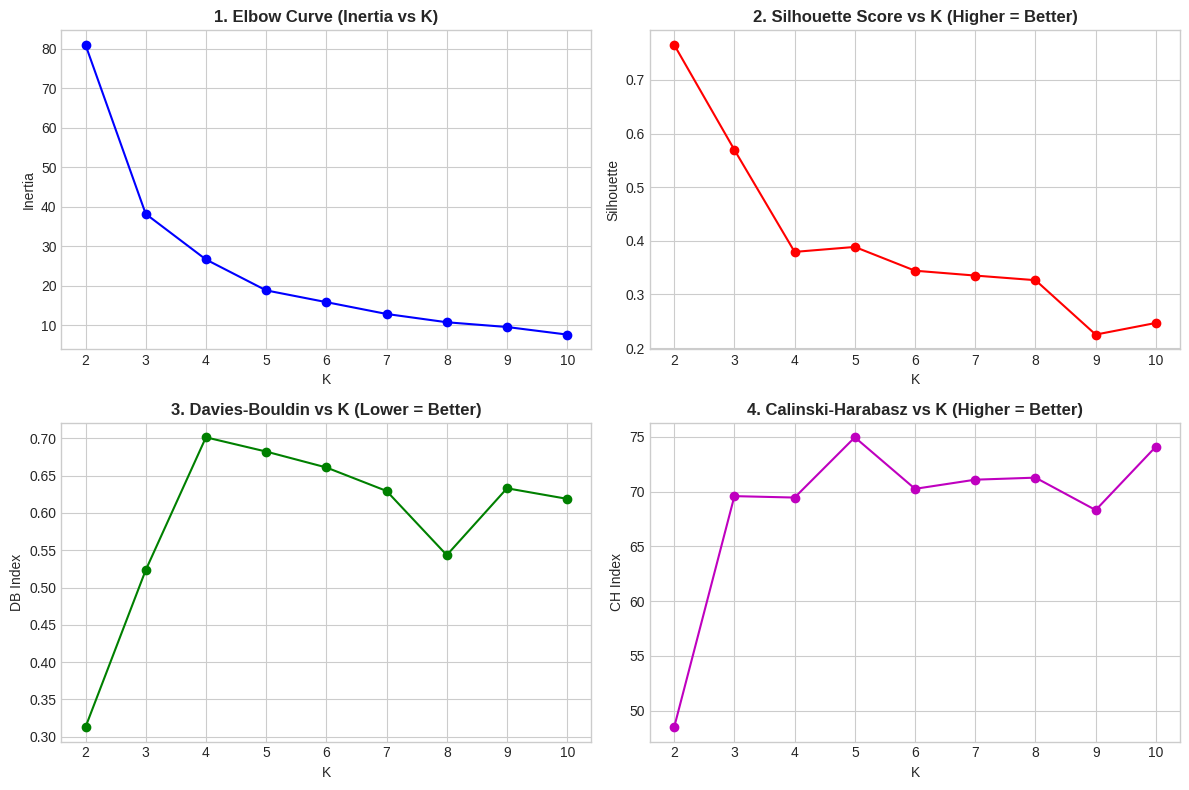

In [13]:
# Grafik Evaluasi K
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(K_range, df_k_table['Inertia'], 'bo-')
axes[0, 0].set_title('1. Elbow Curve (Inertia vs K)', fontweight='bold')
axes[0, 0].set_xlabel('K')
axes[0, 0].set_ylabel('Inertia')

axes[0, 1].plot(K_range, df_k_table['Silhouette'], 'ro-')
axes[0, 1].set_title('2. Silhouette Score vs K (Higher = Better)', fontweight='bold')
axes[0, 1].set_xlabel('K')
axes[0, 1].set_ylabel('Silhouette')

axes[1, 0].plot(K_range, df_k_table['Davies-Bouldin'], 'go-')
axes[1, 0].set_title('3. Davies-Bouldin vs K (Lower = Better)', fontweight='bold')
axes[1, 0].set_xlabel('K')
axes[1, 0].set_ylabel('DB Index')

axes[1, 1].plot(K_range, df_k_table['Calinski-Harabasz'], 'mo-')
axes[1, 1].set_title('4. Calinski-Harabasz vs K (Higher = Better)', fontweight='bold')
axes[1, 1].set_xlabel('K')
axes[1, 1].set_ylabel('CH Index')

plt.tight_layout()
plt.show()

In [14]:
# Komparasi Metrik 3 Algoritma pada K_FINAL = 3
algo_eval = []
for name, lbls in zip(['K-Means', 'Agglomerative', 'Gaussian Mixture'], [labels_km, labels_agg, labels_gmm]):
    algo_eval.append({
        'Algoritma': name,
        'Silhouette Score': silhouette_score(X_scaled, lbls),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, lbls),
        'Calinski-Harabasz Index': calinski_harabasz_score(X_scaled, lbls)
    })

df_algo_comp = pd.DataFrame(algo_eval)
print(f'\n=== PERBANDINGAN METODE CLUSTERING (K_FINAL = {K_FINAL}) ===')
display(df_algo_comp)


=== PERBANDINGAN METODE CLUSTERING (K_FINAL = 3) ===


,Algoritma,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.57,0.52,69.59
1,Agglomerative,0.60,0.45,64.73
2,Gaussian Mixture,0.57,0.52,69.59


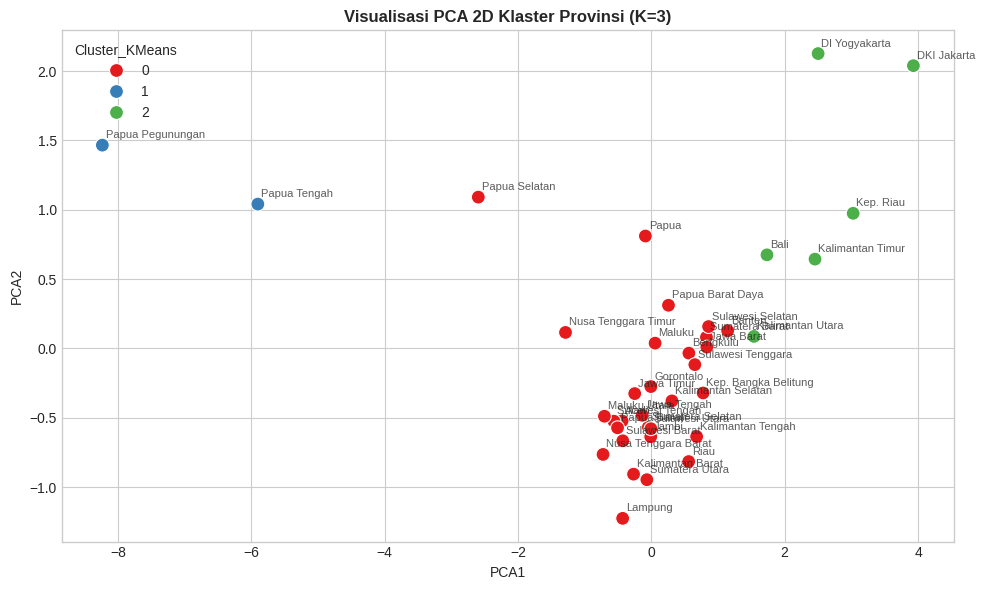

In [15]:
# VISUALISASI PCA 2D
pca_2d = PCA(n_components=2)
pca_coords = pca_2d.fit_transform(X_scaled)
df_cluster['PCA1'] = pca_coords[:, 0]
df_cluster['PCA2'] = pca_coords[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cluster, x='PCA1', y='PCA2', hue='Cluster_KMeans', palette='Set1', s=100)
for i, row in df_cluster.iterrows():
    plt.text(row['PCA1']+0.05, row['PCA2']+0.05, row['Provinsi'], fontsize=8, alpha=0.75)

plt.title(f'Visualisasi PCA 2D Klaster Provinsi (K={K_FINAL})', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [16]:
# Profiling Mean & Median
profile_mean = df_cluster.groupby('Cluster_KMeans')[features_clustering].mean()
profile_median = df_cluster.groupby('Cluster_KMeans')[features_clustering].median()

print('RATA-RATA (MEAN) PER KLASTER K=3')
display(profile_mean)

print('\nMEDIAN PER KLASTER K=3')
display(profile_median)

label_map = {
    2: 'Profil Digital Tinggi (Maju)',
    0: 'Profil Digital Sedang (Berkembang)',
    1: 'Profil Digital Rendah (Tertinggal)'
}
df_cluster['Label_Interpretatif'] = df_cluster['Cluster_KMeans'].map(label_map)

RATA-RATA (MEAN) PER KLASTER K=3


,Penduduk_Akses_Internet,Penduduk_Telepon_Seluler,Penduduk_Menggunakan_Komputer,Rumah_Tangga_Komputer,Rumah_Tangga_Akses_Internet
Cluster_KMeans,,,,,
0,74.07,69.38,11.72,18.68,91.13
1,24.02,29.92,2.78,4.49,34.30
2,85.30,80.08,18.74,31.36,95.77



MEDIAN PER KLASTER K=3


,Penduduk_Akses_Internet,Penduduk_Telepon_Seluler,Penduduk_Menggunakan_Komputer,Rumah_Tangga_Komputer,Rumah_Tangga_Akses_Internet
Cluster_KMeans,,,,,
0,75.81,69.64,11.48,17.73,92.41
1,24.02,29.92,2.78,4.49,34.30
2,83.86,80.81,17.98,31.56,96.12


In [17]:
print('\nDaftar Provinsi Tiap Klaster: ')
for c_id in [2, 0, 1]:
    provs = df_cluster[df_cluster['Cluster_KMeans'] == c_id]['Provinsi'].tolist()
    lbl = label_map[c_id]
    print(f'* Cluster {c_id} [{lbl}] ({len(provs)} Provinsi):')
    print('  ', ', '.join(provs))


Daftar Provinsi Tiap Klaster: 
* Cluster 2 [Profil Digital Tinggi (Maju)] (6 Provinsi):
   Kep. Riau, DKI Jakarta, DI Yogyakarta, Bali, Kalimantan Timur, Kalimantan Utara
* Cluster 0 [Profil Digital Sedang (Berkembang)] (30 Provinsi):
   Aceh, Sumatera Utara, Sumatera Barat, Riau, Jambi, Sumatera Selatan, Bengkulu, Lampung, Kep. Bangka Belitung, Jawa Barat, Jawa Tengah, Jawa Timur, Banten, Nusa Tenggara Barat, Nusa Tenggara Timur, Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan, Sulawesi Utara, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Tenggara, Gorontalo, Sulawesi Barat, Maluku, Maluku Utara, Papua Barat, Papua Barat Daya, Papua, Papua Selatan
* Cluster 1 [Profil Digital Rendah (Tertinggal)] (2 Provinsi):
   Papua Tengah, Papua Pegunungan


In [18]:
# 5.3 EVALUASI FORECASTING & PROYEKSI (2026-2029)
df_fc_eval_all = pd.DataFrame(fc_eval_records)
print('=== TABEL EVALUASI FORECASTING SETIAP INDIKATOR (TESTING 2025) ===')
display(df_fc_eval_all)

print('\n=== MODEL TERPILIH PER INDIKATOR (BASED ON LOWEST MAPE) ===')
for ind, b_m in best_model_per_indicator.items():
    print(f'* {ind}: {b_m}')

# Retraining Full Data 2022-2025 & Forecast 2026-2029
future_years = np.array([2026, 2027, 2028, 2029]).reshape(-1, 1)
final_records = []

for prov in provs_34:
    df_p = df_forecast[df_forecast['Provinsi'] == prov].sort_values('Tahun')
    X_full = df_p[['Tahun']].values

    for _, row in df_p.iterrows():
        for ind in features_clustering:
            final_records.append({
                'Provinsi': prov,
                'Tahun': int(row['Tahun']),
                'Indikator': ind,
                'Nilai': float(row[ind]),
                'Tipe_Data': 'Aktual'
            })

    for ind in features_clustering:
        y_full = df_p[ind].values
        best_m = best_model_per_indicator[ind]

        if best_m == 'Linear Regression':
            m_fit = LinearRegression().fit(X_full, y_full)
            preds = m_fit.predict(future_years)
        elif best_m == 'Polynomial Regression':
            poly = PolynomialFeatures(degree=2)
            X_f_p = poly.fit_transform(X_full)
            future_p = poly.transform(future_years)
            m_fit = LinearRegression().fit(X_f_p, y_full)
            preds = m_fit.predict(future_p)
        elif best_m == 'Holt Exponential Smoothing':
            try:
                holt = Holt(y_full, initialization_method='estimated').fit(smoothing_level=0.8, smoothing_trend=0.2)
                preds = holt.forecast(4)
            except:
                m_fit = LinearRegression().fit(X_full, y_full)
                preds = m_fit.predict(future_years)

        for yr, pr in zip([2026, 2027, 2028, 2029], preds):
            val_capped = min(100.0, max(0.0, float(pr)))
            final_records.append({
                'Provinsi': prov,
                'Tahun': yr,
                'Indikator': ind,
                'Nilai': val_capped,
                'Tipe_Data': 'Forecast'
            })

df_final_all = pd.DataFrame(final_records)


=== TABEL EVALUASI FORECASTING SETIAP INDIKATOR (TESTING 2025) ===


,Indikator,Model,MAE,RMSE,MAPE (%)
0,Penduduk_Akses_Internet,Linear Regression,2.40,3.25,3.29
1,Penduduk_Akses_Internet,Polynomial Regression,3.58,6.94,4.99
2,Penduduk_Akses_Internet,Holt Exponential Smoothing,2.44,3.47,3.36
3,Penduduk_Telepon_Seluler,Linear Regression,2.50,3.12,3.54
4,Penduduk_Telepon_Seluler,Polynomial Regression,3.09,6.12,4.38
5,Penduduk_Telepon_Seluler,Holt Exponential Smoothing,2.43,3.28,3.45
6,Penduduk_Menggunakan_Komputer,Linear Regression,1.02,1.29,7.85
7,Penduduk_Menggunakan_Komputer,Polynomial Regression,2.96,4.03,22.26
8,Penduduk_Menggunakan_Komputer,Holt Exponential Smoothing,1.05,1.35,8.10
9,Rumah_Tangga_Komputer,Linear Regression,1.47,1.90,7.31



=== MODEL TERPILIH PER INDIKATOR (BASED ON LOWEST MAPE) ===
* Penduduk_Akses_Internet: Linear Regression
* Penduduk_Telepon_Seluler: Holt Exponential Smoothing
* Penduduk_Menggunakan_Komputer: Linear Regression
* Rumah_Tangga_Komputer: Holt Exponential Smoothing
* Rumah_Tangga_Akses_Internet: Holt Exponential Smoothing


In [19]:
# ==========================================
# 5.4 PERBANDINGAN AKTUAL 2025 VS PREDIKSI 3 MODEL (PER PROVINSI)
# Training: 2022-2024  |  Target validasi: 2025
# ==========================================

validasi_rows = []

for prov in provs_34:
    df_p = df_forecast[df_forecast['Provinsi'] == prov].sort_values('Tahun')
    train = df_p[df_p['Tahun'] <= 2024]
    test  = df_p[df_p['Tahun'] == 2025]

    X_tr = train[['Tahun']].values
    X_te = test[['Tahun']].values

    for ind in features_clustering:
        y_tr = train[ind].values
        aktual = float(test[ind].values[0])

        # --- Linear Regression ---
        lr = LinearRegression()
        lr.fit(X_tr, y_tr)
        pred_lr = round(min(100.0, max(0.0, float(lr.predict(X_te)[0]))), 2)

        # --- Polynomial Regression (degree=2) ---
        poly = PolynomialFeatures(degree=2)
        lr2 = LinearRegression()
        lr2.fit(poly.fit_transform(X_tr), y_tr)
        pred_poly = round(min(100.0, max(0.0, float(lr2.predict(poly.transform(X_te))[0]))), 2)

        # --- Holt Exponential Smoothing ---
        try:
            holt = Holt(y_tr, initialization_method='estimated').fit(smoothing_level=0.8, smoothing_trend=0.2)
            pred_holt = round(min(100.0, max(0.0, float(holt.forecast(1)[0]))), 2)
        except:
            pred_holt = round(pred_lr, 2)

        bm = best_model_per_indicator[ind]
        pred_best = {
            'Linear Regression': pred_lr,
            'Polynomial Regression': pred_poly,
            'Holt Exponential Smoothing': pred_holt
        }[bm]
        selisih = round(pred_best - aktual, 2)

        validasi_rows.append({
            'Provinsi': prov,
            'Indikator': ind,
            'Aktual 2025': round(aktual, 2),
            'Pred. Linear Reg.': pred_lr,
            'Pred. Polynomial Reg.': pred_poly,
            'Pred. Holt Exp. Smoothing': pred_holt,
            'Model Terbaik': bm,
            'Prediksi Terbaik': round(pred_best, 2),
            'Selisih (Pred-Aktual)': selisih,
        })

df_validasi = pd.DataFrame(validasi_rows)

print('=== PERBANDINGAN AKTUAL 2025 VS PREDIKSI 3 MODEL (TRAINING 2022-2024) ===')
display(df_validasi)


=== PERBANDINGAN AKTUAL 2025 VS PREDIKSI 3 MODEL (TRAINING 2022-2024) ===


,Provinsi,Indikator,Aktual 2025,Pred. Linear Reg.,Pred. Polynomial Reg.,Pred. Holt Exp. Smoothing,Model Terbaik,Prediksi Terbaik,Selisih (Pred-Aktual)
0,Aceh,Penduduk_Akses_Internet,70.03,68.35,63.88,68.14,Linear Regression,68.35,-1.68
1,Aceh,Penduduk_Telepon_Seluler,68.21,65.38,67.96,65.50,Holt Exponential Smoothing,65.50,-2.71
2,Aceh,Penduduk_Menggunakan_Komputer,10.14,9.62,9.12,9.60,Linear Regression,9.62,-0.52
3,Aceh,Rumah_Tangga_Komputer,17.59,16.55,14.87,16.47,Holt Exponential Smoothing,16.47,-1.12
4,Aceh,Rumah_Tangga_Akses_Internet,91.91,94.19,87.32,93.86,Holt Exponential Smoothing,93.86,1.95
...,...,...,...,...,...,...,...,...,...
165,Papua,Penduduk_Akses_Internet,64.64,75.40,100.00,77.66,Linear Regression,75.40,10.76
166,Papua,Penduduk_Telepon_Seluler,68.56,79.72,100.00,81.87,Holt Exponential Smoothing,81.87,13.31
167,Papua,Penduduk_Menggunakan_Komputer,13.68,16.33,26.81,16.82,Linear Regression,16.33,2.65
168,Papua,Rumah_Tangga_Komputer,23.14,29.81,53.76,30.94,Holt Exponential Smoothing,30.94,7.80


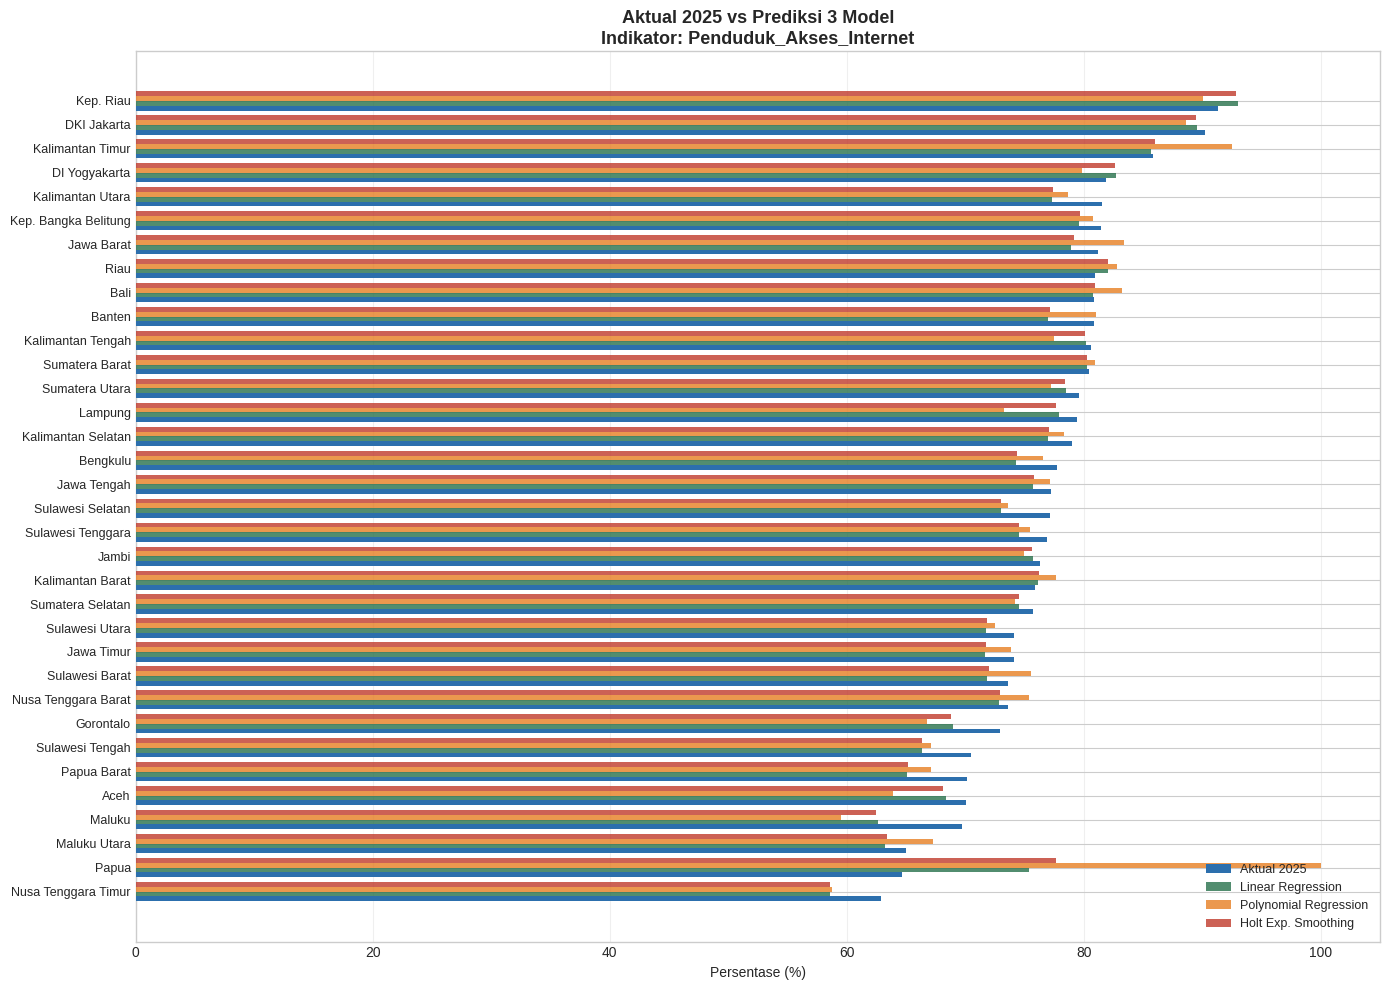


=== SELISIH MODEL TERBAIK vs AKTUAL 2025 (Penduduk_Akses_Internet) ===


,Provinsi,Aktual 2025,Model Terbaik,Prediksi Terbaik,Selisih (Pred-Aktual)
0,Papua,64.64,Linear Regression,75.40,10.76
1,Maluku,69.74,Linear Regression,62.65,-7.09
2,Papua Barat,70.17,Linear Regression,65.10,-5.07
3,Nusa Tenggara Timur,62.91,Linear Regression,58.55,-4.36
4,Kalimantan Utara,81.58,Linear Regression,77.31,-4.27
5,Sulawesi Tengah,70.50,Linear Regression,66.33,-4.17
6,Sulawesi Selatan,77.17,Linear Regression,73.02,-4.15
7,Gorontalo,72.93,Linear Regression,68.94,-3.99
8,Banten,80.83,Linear Regression,76.98,-3.85
9,Bengkulu,77.75,Linear Regression,74.28,-3.47


Rata-rata |selisih|: 2.40%
Selisih maks       : 10.76% (Papua)
Selisih min        : 0.08% (Bali)


In [20]:
# ==========================================
# 5.5 VISUALISASI AKTUAL VS PREDIKSI 2025 PER PROVINSI
# Ganti IND_TAMPIL untuk melihat indikator lain
# ==========================================

IND_TAMPIL = 'Penduduk_Akses_Internet'
# Pilihan lain: 'Penduduk_Telepon_Seluler', 'Penduduk_Menggunakan_Komputer',
#               'Rumah_Tangga_Komputer', 'Rumah_Tangga_Akses_Internet'

df_viz = df_validasi[df_validasi['Indikator'] == IND_TAMPIL].sort_values('Aktual 2025', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 10))
x = range(len(df_viz))
w = 0.2

ax.barh([i - 1.5*w for i in x], df_viz['Aktual 2025'],                height=w, label='Aktual 2025',               color='#2c6fad', zorder=3)
ax.barh([i - 0.5*w for i in x], df_viz['Pred. Linear Reg.'],          height=w, label='Linear Regression',          color='#27714b', alpha=0.8, zorder=3)
ax.barh([i + 0.5*w for i in x], df_viz['Pred. Polynomial Reg.'],      height=w, label='Polynomial Regression',      color='#e67e22', alpha=0.8, zorder=3)
ax.barh([i + 1.5*w for i in x], df_viz['Pred. Holt Exp. Smoothing'], height=w, label='Holt Exp. Smoothing',        color='#c0392b', alpha=0.8, zorder=3)

ax.set_yticks(list(x))
ax.set_yticklabels(df_viz['Provinsi'].tolist(), fontsize=9)
ax.set_xlabel('Persentase (%)', fontsize=10)
ax.set_title(f'Aktual 2025 vs Prediksi 3 Model\nIndikator: {IND_TAMPIL}', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

# Tabel ringkasan selisih
print(f'\n=== SELISIH MODEL TERBAIK vs AKTUAL 2025 ({IND_TAMPIL}) ===')
sub = (df_validasi[df_validasi['Indikator'] == IND_TAMPIL]
       [['Provinsi', 'Aktual 2025', 'Model Terbaik', 'Prediksi Terbaik', 'Selisih (Pred-Aktual)']]
       .sort_values('Selisih (Pred-Aktual)', key=abs, ascending=False)
       .reset_index(drop=True))
display(sub)
kolom_selisih = 'Selisih (Pred-Aktual)'
print(f'Rata-rata |selisih|: {sub[kolom_selisih].abs().mean():.2f}%')
print(f'Selisih maks       : {sub[kolom_selisih].abs().max():.2f}% ({sub.loc[sub[kolom_selisih].abs().idxmax(), "Provinsi"]})')
print(f'Selisih min        : {sub[kolom_selisih].abs().min():.2f}% ({sub.loc[sub[kolom_selisih].abs().idxmin(), "Provinsi"]})')


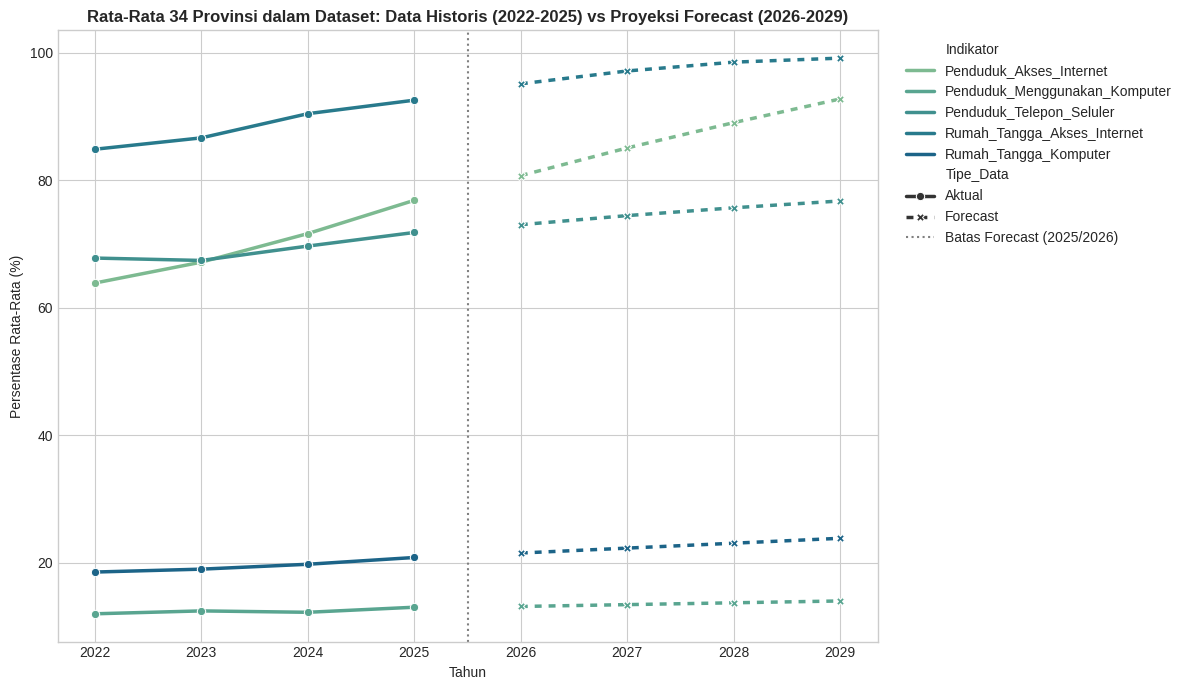

In [21]:
# Visualisasi Aktual vs Forecast
df_avg_34 = df_final_all.groupby(['Tahun', 'Indikator', 'Tipe_Data'])['Nilai'].mean().reset_index()
plt.figure(figsize=(12, 7))
sns.lineplot(data=df_avg_34, x='Tahun', y='Nilai', hue='Indikator', style='Tipe_Data', markers=True, dashes={'Aktual': '', 'Forecast': (2, 2)}, linewidth=2.5)
plt.axvline(2025.5, color='gray', linestyle=':', label='Batas Forecast (2025/2026)')
plt.title('Rata-Rata 34 Provinsi dalam Dataset: Data Historis (2022-2025) vs Proyeksi Forecast (2026-2029)', fontsize=12, fontweight='bold')
plt.ylabel('Persentase Rata-Rata (%)')
plt.xlabel('Tahun')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [22]:
# Menampilkan rata-rata nasional proyeksi hasil forecast 2026-2029
df_forecast_summary = df_final_all[df_final_all['Tipe_Data'] == 'Forecast'].groupby(['Tahun', 'Indikator'])['Nilai'].mean().unstack()
print('=== RATA-RATA NASIONAL PROYEKSI FORECAST (2026-2029) ===')
display(df_forecast_summary)

=== RATA-RATA NASIONAL PROYEKSI FORECAST (2026-2029) ===


Indikator,Penduduk_Akses_Internet,Penduduk_Menggunakan_Komputer,Penduduk_Telepon_Seluler,Rumah_Tangga_Akses_Internet,Rumah_Tangga_Komputer
Tahun,,,,,
2026,80.75,13.11,73.04,95.16,21.50
2027,85.10,13.40,74.47,97.18,22.27
2028,89.07,13.69,75.70,98.56,23.04
2029,92.79,13.97,76.77,99.19,23.81


# 6. DEPLOYMENT

Pada fase Deployment CRISP-DM, artefak hasil pemodelan disimpan secara permanen dan disiapkan untuk integrasi aplikasi:
1. Penyimpanan Model ML (.joblib)
2. Penyimpanan Hasil Clustering & Forecasting (.csv)
3. Integrasi Dashboard Streamlit (app.py)

In [23]:
# 6. DEPLOYMENT: SIMPAN ARTEFAK MODEL & DATASET FINAL
os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

# 1. Simpan Model Machine Learning (.joblib)
joblib.dump(scaler, 'models/scaler.joblib')
joblib.dump(km_final, 'models/kmeans_model.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(km_final, 'kmeans_model.joblib')
print('[DEPLOYMENT 1/3] Model Machine Learning berhasil disimpan (`models/scaler.joblib`, `models/kmeans_model.joblib`).')

# 2. Simpan Dataset Hasil Clustering 2025 & Hasil Proyeksi 2026-2029 (.csv)
file_output_cluster = 'dataset_clustering_2025_dengan_cluster.csv'
file_output_forecast = 'hasil_forecasting_2026_2029_34_provinsi.csv'

df_cluster.to_csv(file_output_cluster, index=False)
df_cluster.to_csv(os.path.join('data', file_output_cluster), index=False)

df_final_all.to_csv(file_output_forecast, index=False)
df_final_all.to_csv(os.path.join('data', file_output_forecast), index=False)
print(f'[DEPLOYMENT 2/3] Dataset Clustering disimpan: `{file_output_cluster}`')
print(f'[DEPLOYMENT 2/3] Dataset Forecasting disimpan: `{file_output_forecast}`')

# 3. Petunjuk Eksekusi Dashboard Streamlit
print('\n' + '='*60)
print('[DEPLOYMENT 3/3] PETUNJUK PENJALANAN DASHBOARD STREAMLIT')
print('='*60)
print('Seluruh model dan dataset hasil proyeksi telah siap digunakan oleh aplikasi Streamlit.')
print('Untuk menjalankan dashboard interaktif `app.py`, jalankan perintah berikut di terminal/prompt:')
print('    streamlit run app.py')
print('='*60)

[DEPLOYMENT 1/3] Model Machine Learning berhasil disimpan (`models/scaler.joblib`, `models/kmeans_model.joblib`).
[DEPLOYMENT 2/3] Dataset Clustering disimpan: `dataset_clustering_2025_dengan_cluster.csv`
[DEPLOYMENT 2/3] Dataset Forecasting disimpan: `hasil_forecasting_2026_2029_34_provinsi.csv`

[DEPLOYMENT 3/3] PETUNJUK PENJALANAN DASHBOARD STREAMLIT
Seluruh model dan dataset hasil proyeksi telah siap digunakan oleh aplikasi Streamlit.
Untuk menjalankan dashboard interaktif `app.py`, jalankan perintah berikut di terminal/prompt:
    streamlit run app.py


# 7. KESIMPULAN

Kesimpulan ini menjawab kelima rumusan masalah berdasarkan angka aktual hasil analisis dengan $K=3$.

1. **Karakteristik Digital Antarprovinsi (2025):**
   Terdapat disparitas TIK yang nyata antarprovinsi. Wilayah pusat ekonomi dan pariwisata memiliki penetrasi TIK sangat tinggi (>85%), mayoritas provinsi berada pada tingkat sedang (70–80%), sedangkan wilayah pemekaran baru di Papua (Papua Tengah dan Papua Pegunungan) berada pada tingkat adopsi TIK sangat rendah (<35%).

2. **Jumlah Klaster Optimum ($K=3$):**
   $K=3$ ditetapkan sebagai jumlah klaster final karena berada pada titik *Elbow* paling tajam dengan penurunan *Inertia* sebesar **52.8%**, serta menghasilkan *Silhouette Score* yang tinggi (**0.57**), *Davies-Bouldin Index* yang rendah (**0.52**), dan *Calinski-Harabasz Index* sebesar **69.59**. Hasil ini juga sejalan dengan interpretasi domain TIK, yaitu tingkat Tinggi, Sedang, dan Rendah.

3. **Profil Masing-Masing Klaster:**

   | Klaster | Jumlah | Provinsi |
   |---|---|---|
   | **Profil Digital Tinggi (Maju)** | 6 | Kep. Riau, DKI Jakarta, DI Yogyakarta, Bali, Kalimantan Timur, Kalimantan Utara |
   | **Profil Digital Sedang (Berkembang)** | 30 | Seluruh provinsi lainnya |
   | **Profil Digital Rendah (Tertinggal)** | 2 | Papua Tengah, Papua Pegunungan |

   Selisih rata-rata akses internet antara klaster Tinggi dan Rendah mencapai **61.28 poin persentase**, yang menunjukkan jurang kesenjangan digital yang sangat lebar.

4. **Perkembangan Indikator Digital (2022–2025):**
   Rata-rata 34 provinsi dengan data historis lengkap menunjukkan tren pertumbuhan positif pada kelima indikator. `Penduduk_Akses_Internet` mencatatkan kenaikan yang paling konsisten.

5. **Model Forecasting Terpilih per Indikator (MAPE terendah pada data uji 2025):**

   | Indikator | Model terpilih | MAPE |
   |---|---|---|
   | `Penduduk_Akses_Internet` | Linear Regression | 3.29% |
   | `Penduduk_Telepon_Seluler` | Holt Exponential Smoothing | 3.45% |
   | `Penduduk_Menggunakan_Komputer` | Linear Regression | 7.85% |
   | `Rumah_Tangga_Komputer` | Holt Exponential Smoothing | 7.23% |
   | `Rumah_Tangga_Akses_Internet` | Holt Exponential Smoothing | 1.58% |

   Linear Regression dan Holt Exponential Smoothing memberikan performa terbaik dengan MAPE di bawah 8% untuk seluruh indikator. Polynomial Regression menghasilkan galat pengujian yang lebih tinggi pada indikator tertentu, sehingga tidak terpilih.

6. **Hasil Proyeksi 2026–2029:**
   Proyeksi pada 34 provinsi menunjukkan rata-rata persentase `Penduduk_Akses_Internet` terus naik: **80.75% (2026), 85.10% (2027), 89.07% (2028), dan 92.79% (2029)**. Pada periode yang sama, `Rumah_Tangga_Akses_Internet` diproyeksikan mendekati batas jenuh, yaitu **99.19% pada 2029**.

7. **Keterbatasan dan Saran:**
   * Empat provinsi pemekaran Papua tidak diproyeksikan karena data historisnya tidak lengkap.
   * Proyeksi hanya bersumber dari **4 titik tahun (2022–2025)**, sehingga hasilnya sebaiknya dibaca sebagai indikasi arah tren, bukan angka pasti.
   * Pada $K=3$, klaster Rendah hanya beranggotakan 2 provinsi. Hal ini mencerminkan kesenjangan ekstrem antara wilayah Papua pemekaran dan provinsi lainnya.
   * Untuk penelitian lanjutan, data tingkat kabupaten/kota dapat memberikan pemetaan yang lebih rinci, dan model dengan variabel eksogen (infrastruktur, pendapatan, pendidikan) dapat memperbaiki akurasi proyeksi.